# Basics of NLP
Learning how computers read and clean text, one step at a time.

## Setup

In [1]:
import nltk
import string

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

True

## 1. Our Text

In [2]:
text = "The children were playing happily in the park. They were running, jumping and laughing loudly! Their teacher was watching them from a bench. Later, the kids ate delicious mangoes and went home. The children loved the park and want to play there again tomorrow."
print(text)

The children were playing happily in the park. They were running, jumping and laughing loudly! Their teacher was watching them from a bench. Later, the kids ate delicious mangoes and went home. The children loved the park and want to play there again tomorrow.


## 2. Lowercasing

In [3]:
lower_text = text.lower()
print(lower_text)

the children were playing happily in the park. they were running, jumping and laughing loudly! their teacher was watching them from a bench. later, the kids ate delicious mangoes and went home. the children loved the park and want to play there again tomorrow.


## 3. Removing Punctuation

In [4]:
print(string.punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [5]:
clean_text = lower_text.translate(str.maketrans('', '', string.punctuation))
print(clean_text)

the children were playing happily in the park they were running jumping and laughing loudly their teacher was watching them from a bench later the kids ate delicious mangoes and went home the children loved the park and want to play there again tomorrow


## 4. Stop Words

In [6]:
words = clean_text.split()
print(words)

['the', 'children', 'were', 'playing', 'happily', 'in', 'the', 'park', 'they', 'were', 'running', 'jumping', 'and', 'laughing', 'loudly', 'their', 'teacher', 'was', 'watching', 'them', 'from', 'a', 'bench', 'later', 'the', 'kids', 'ate', 'delicious', 'mangoes', 'and', 'went', 'home', 'the', 'children', 'loved', 'the', 'park', 'and', 'want', 'to', 'play', 'there', 'again', 'tomorrow']


In [7]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
print("Number of stop words:", len(stop_words))
print(sorted(stop_words)[:40])

Number of stop words: 198
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don']


In [8]:
filtered_words = [word for word in words if word not in stop_words]

print("Before:", words)
print("After :", filtered_words)

Before: ['the', 'children', 'were', 'playing', 'happily', 'in', 'the', 'park', 'they', 'were', 'running', 'jumping', 'and', 'laughing', 'loudly', 'their', 'teacher', 'was', 'watching', 'them', 'from', 'a', 'bench', 'later', 'the', 'kids', 'ate', 'delicious', 'mangoes', 'and', 'went', 'home', 'the', 'children', 'loved', 'the', 'park', 'and', 'want', 'to', 'play', 'there', 'again', 'tomorrow']
After : ['children', 'playing', 'happily', 'park', 'running', 'jumping', 'laughing', 'loudly', 'teacher', 'watching', 'bench', 'later', 'kids', 'ate', 'delicious', 'mangoes', 'went', 'home', 'children', 'loved', 'park', 'want', 'play', 'tomorrow']


## 5. Stemming

In [9]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

for word in ["playing", "played", "plays", "studies", "running", "better"]:
    print(word, "→", stemmer.stem(word))

playing → play
played → play
plays → play
happily → happili
studies → studi
running → run
better → better


## 6. Lemmatization

In [10]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

for word in ["children", "mangoes", "mice", "leaves", "geese"]:
    print(word, "→", lemmatizer.lemmatize(word))

children → child
mangoes → mango
mice → mouse
leaves → leaf
geese → goose


In [11]:
for word in ["running", "ate", "went", "was", "studies"]:
    print(word, "→", lemmatizer.lemmatize(word, pos='v'))

running → run
ate → eat
went → go
was → be
studies → study


In [12]:
for word in ["better", "happier", "best"]:
    print(word, "→", lemmatizer.lemmatize(word, pos='a'))

better → good
happier → happy
best → best


## 7. Stemming vs Lemmatization

In [13]:
print(f"{'Word':<12}{'Stem':<12}{'Lemma':<12}")
print("-" * 36)

examples = [("studies", "v"), ("running", "v"), ("went", "v"), ("flies", "n"), ("children", "n"), ("better", "a")]

for word, pos in examples:
    print(f"{word:<12}{stemmer.stem(word):<12}{lemmatizer.lemmatize(word, pos=pos):<12}")

Word        Stem        Lemma       
------------------------------------
studies     studi       study       
running     run         run         
went        went        go          
flies       fli         fly         
children    children    child       
better      better      good        


## 8. Parts of Speech (POS) Tagging

In [14]:
from nltk import pos_tag

sample = "The little cat is sleeping on the warm mat".split()
print(pos_tag(sample))

[('The', 'DT'), ('little', 'JJ'), ('cat', 'NN'), ('is', 'VBZ'), ('sleeping', 'VBG'), ('on', 'IN'), ('the', 'DT'), ('warm', 'JJ'), ('mat', 'NN')]


In [15]:
print(pos_tag(filtered_words))

[('children', 'NNS'), ('playing', 'VBG'), ('happily', 'RB'), ('park', 'NN'), ('running', 'VBG'), ('jumping', 'VBG'), ('laughing', 'VBG'), ('loudly', 'RB'), ('teacher', 'RB'), ('watching', 'VBG'), ('bench', 'NN'), ('later', 'RB'), ('kids', 'NNS'), ('ate', 'VBP'), ('delicious', 'JJ'), ('mangoes', 'NNS'), ('went', 'VBD'), ('home', 'NN'), ('children', 'NNS'), ('loved', 'VBD'), ('park', 'NN'), ('want', 'VBP'), ('play', 'NN'), ('tomorrow', 'NN')]


## 9. Word Frequency

In [16]:
from nltk import FreqDist

freq = FreqDist(filtered_words)
print(freq.most_common(5))

[('children', 2), ('park', 2), ('playing', 1), ('happily', 1), ('running', 1)]


<Axes: xlabel='Samples', ylabel='Counts'>

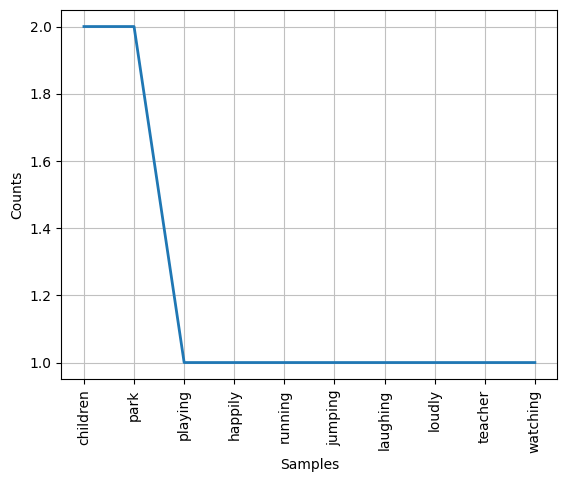

In [17]:
freq.plot(10)

## 10. Putting It All Together

In [18]:
def get_pos(tag):
    return {'J': 'a', 'V': 'v', 'R': 'r'}.get(tag[0], 'n')


def preprocess(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = text.split()
    words = [word for word in words if word not in stop_words]
    tagged = pos_tag(words)
    return [lemmatizer.lemmatize(word, get_pos(tag)) for word, tag in tagged]

In [19]:
print(preprocess(text))

['child', 'play', 'happily', 'park', 'run', 'jump', 'laugh', 'loudly', 'teacher', 'watch', 'bench', 'later', 'kid', 'eat', 'delicious', 'mango', 'go', 'home', 'child', 'love', 'park', 'want', 'play', 'tomorrow']


## 11. Try Your Own Sentence

In [ ]:
my_text = input("Type a sentence: ")
print(preprocess(my_text))